### PII Masking Baseline with BiLSTM

This notebook replaces the old binary private/non-private classifier with a token-level PII masking baseline. The goal is to keep useful safe text while masking only private spans before anything is passed forward.

#### Imports, paths, and setup

This notebook is configured for a real baseline run by default. It uses full examples, dynamic padding during batching, and type-specific BIO labels.

In [1]:
import ast
import json
import random
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def find_repo_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "README.md").exists() and (candidate / "model").exists():
            return candidate
    raise RuntimeError("Could not find repo root. Run this notebook from the repo root or model/baseline_model.")

REPO_ROOT = find_repo_root()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Repo root:", REPO_ROOT)
print("Device:", device)

Matplotlib is building the font cache; this may take a moment.
<REPO_ROOT>/.venv/Lib/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repo root: <LOCAL_PATH>/Home-AI
Device: cuda


#### Load the dataset and inspect columns

The model input is `source_text`. The masked `target_text` is not used as input because that would leak the answer into training. It can be used only as a reference output.

In [2]:
DATASET_NAME = "ai4privacy/pii-masking-300k"

dataset = load_dataset(DATASET_NAME)

print(dataset)
for split_name, split_data in dataset.items():
    print(f"{split_name}: {split_data.num_rows:,} rows")
    print("Columns:", split_data.column_names)

main_split_name = "train" if "train" in dataset else list(dataset.keys())[0]
raw_df = dataset[main_split_name].to_pandas()

print("\nUsing split:", main_split_name)
print("Raw rows:", len(raw_df))
print("Raw columns:", list(raw_df.columns))

sample_summary = {column: type(raw_df.iloc[0][column]).__name__ for column in raw_df.columns}
print("\nSample value types:")
print(sample_summary)

DatasetDict({
    train: Dataset({
        features: ['source_text', 'target_text', 'privacy_mask', 'span_labels', 'mbert_text_tokens', 'mbert_bio_labels', 'id', 'language', 'set'],
        num_rows: 177677
    })
    validation: Dataset({
        features: ['source_text', 'target_text', 'privacy_mask', 'span_labels', 'mbert_text_tokens', 'mbert_bio_labels', 'id', 'language', 'set'],
        num_rows: 47728
    })
})
train: 177,677 rows
Columns: ['source_text', 'target_text', 'privacy_mask', 'span_labels', 'mbert_text_tokens', 'mbert_bio_labels', 'id', 'language', 'set']
validation: 47,728 rows
Columns: ['source_text', 'target_text', 'privacy_mask', 'span_labels', 'mbert_text_tokens', 'mbert_bio_labels', 'id', 'language', 'set']

Using split: train
Raw rows: 177677
Raw columns: ['source_text', 'target_text', 'privacy_mask', 'span_labels', 'mbert_text_tokens', 'mbert_bio_labels', 'id', 'language', 'set']

Sample value types:
{'source_text': 'str', 'target_text': 'str', 'privacy_mask': '

#### Clean and filter rows

The cleaning is intentionally simple: strip whitespace, normalize repeated whitespace, remove rows with missing or empty `source_text`, and remove duplicate `source_text` values. Short but valid examples are kept. If a language column exists, `LANGUAGE_FILTER` controls whether we keep only English or keep all languages.

In [3]:
LANGUAGE_FILTER = "en"  # Set to None to keep all languages.

def normalize_text(text):
    text = str(text).strip()
    text = re.sub(r"\s+", " ", text)
    return text

def detect_language_column(df):
    for column in ["language", "lang", "locale"]:
        if column in df.columns:
            return column
    return None

if "source_text" not in raw_df.columns:
    raise ValueError("Expected a source_text column in the dataset.")

df = raw_df.copy()
df = df[df["source_text"].notna()].copy()
df["source_text"] = df["source_text"].apply(normalize_text)
df = df[df["source_text"].str.len() > 0].copy()

language_column = detect_language_column(df)
if LANGUAGE_FILTER and language_column:
    before = len(df)
    allowed = {LANGUAGE_FILTER.lower(), "english" if LANGUAGE_FILTER.lower() == "en" else LANGUAGE_FILTER.lower()}
    df = df[df[language_column].astype(str).str.lower().isin(allowed)]
    print(f"Language filter kept {len(df):,} of {before:,} rows using {language_column}={LANGUAGE_FILTER!r}.")
elif LANGUAGE_FILTER:
    print("No language column found; keeping all rows.")

df = df.drop_duplicates(subset=["source_text"]).reset_index(drop=True)

print("Rows after cleaning/filtering:", len(df))
print("Columns available for labels:", [c for c in ["privacy_mask", "span_labels", "mberttokens", "mbert_bio_labels", "target_text"] if c in df.columns])
length_preview = df["source_text"].str.len().head(5).tolist()
print("Example source_text lengths:", length_preview)

Language filter kept 29,908 of 177,652 rows using language='en'.
Rows after cleaning/filtering: 29908
Columns available for labels: ['privacy_mask', 'span_labels', 'mbert_bio_labels', 'target_text']
Example source_text lengths: [450, 451, 408, 383, 412]


#### Convert privacy spans into token labels

The preferred path is `source_text` plus `privacy_mask`, with `span_labels` as a fallback. The tokenizer keeps character offsets so privacy spans become type-specific BIO labels from the dataset. `O` means the token is not private.

In [4]:
TOKEN_PATTERN = re.compile(r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}|\d+[\d.,:/+-]*|[A-Za-z]+(?:[-'][A-Za-z]+)*|\w+|[^\w\s]", re.UNICODE)

def parse_annotation_value(value):
    if value is None:
        return []
    if isinstance(value, float) and pd.isna(value):
        return []
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, list):
        return value
    if isinstance(value, tuple):
        return list(value)
    if isinstance(value, str):
        value = value.strip()
        if not value:
            return []
        try:
            parsed = ast.literal_eval(value)
            return parsed if isinstance(parsed, list) else []
        except (SyntaxError, ValueError):
            return []
    return []

def normalize_entity_label(label):
    if label is None:
        return "UNKNOWN"
    label = str(label).strip()
    if not label:
        return "UNKNOWN"
    label = re.sub(r"^[BI]-", "", label, flags=re.IGNORECASE)
    label = re.sub(r"[^A-Za-z0-9]+", "_", label).strip("_").upper()
    return label or "UNKNOWN"

def get_dict_value(item, keys):
    for key in keys:
        if key in item and item[key] not in [None, ""]:
            return item[key]
    return None

def find_value_span(text, value, start_at=0):
    if not value:
        return None
    value = str(value)
    start = text.find(value, start_at)
    if start == -1:
        start = text.find(value)
    if start == -1:
        return None
    return start, start + len(value)

def extract_spans_from_privacy_mask(text, value):
    spans = []
    cursor = 0
    for item in parse_annotation_value(value):
        if not isinstance(item, dict):
            continue
        label = normalize_entity_label(get_dict_value(item, ["label", "entity", "entity_type", "type"]))
        start = get_dict_value(item, ["start", "start_offset", "begin"])
        end = get_dict_value(item, ["end", "end_offset", "stop"])
        mask_value = get_dict_value(item, ["value", "text", "source_value", "original"])

        if start is None or end is None:
            found = find_value_span(text, mask_value, cursor)
            if not found:
                continue
            start, end = found
        else:
            start, end = int(start), int(end)

        if 0 <= start < end <= len(text):
            spans.append({"start": start, "end": end, "label": label})
            cursor = end
    return spans

def extract_spans_from_span_labels(text, value):
    spans = []
    for item in parse_annotation_value(value):
        label = None
        start = None
        end = None
        if isinstance(item, dict):
            label = get_dict_value(item, ["label", "entity", "entity_type", "type"])
            start = get_dict_value(item, ["start", "start_offset", "begin"])
            end = get_dict_value(item, ["end", "end_offset", "stop"])
        elif isinstance(item, (list, tuple)) and len(item) >= 3:
            if isinstance(item[0], (int, np.integer)):
                start, end, label = item[0], item[1], item[2]
            else:
                label, start, end = item[0], item[1], item[2]
        if start is None or end is None:
            continue
        start, end = int(start), int(end)
        if 0 <= start < end <= len(text):
            spans.append({"start": start, "end": end, "label": normalize_entity_label(label)})
    return spans

def tokenize_with_offsets(text):
    tokens = []
    offsets = []
    for match in TOKEN_PATTERN.finditer(text):
        tokens.append(match.group(0))
        offsets.append((match.start(), match.end()))
    return tokens, offsets

def spans_to_bio_labels(offsets, spans):
    labels = ["O"] * len(offsets)
    for span in sorted(spans, key=lambda item: (item["start"], item["end"])):
        first_token = True
        entity = span["label"]
        for i, (token_start, token_end) in enumerate(offsets):
            overlaps = token_start < span["end"] and token_end > span["start"]
            if overlaps:
                prefix = "B" if first_token else "I"
                labels[i] = f"{prefix}-{entity}"
                first_token = False
    return labels

def build_labeled_example(row):
    text = row["source_text"]
    spans = []
    if "privacy_mask" in row.index:
        spans = extract_spans_from_privacy_mask(text, row["privacy_mask"])
    if not spans and "span_labels" in row.index:
        spans = extract_spans_from_span_labels(text, row["span_labels"])
    tokens, offsets = tokenize_with_offsets(text)
    labels = spans_to_bio_labels(offsets, spans)
    return {
        "source_text": text,
        "tokens": tokens,
        "offsets": offsets,
        "labels": labels,
        "spans": spans,
        "target_text": row["target_text"] if "target_text" in row.index else None,
    }

examples = [build_labeled_example(row) for _, row in df.iterrows()]
examples = [ex for ex in examples if ex["tokens"] and ex["spans"] and len(ex["tokens"]) == len(ex["labels"])]

entity_counter = Counter(span["label"] for ex in examples for span in ex["spans"])
token_label_counter = Counter(label for ex in examples for label in ex["labels"])

print("Labeled examples:", len(examples))
print("Top original entity labels:", entity_counter.most_common(15))
print("Top token labels:", token_label_counter.most_common(15))
if examples:
    first = examples[0]
    print("Example token count:", len(first["tokens"]))
    print("Example label count:", len(first["labels"]))
    print("Example span count:", len(first["spans"]))

Labeled examples: 26109
Top original entity labels: [('TIME', 12776), ('USERNAME', 10309), ('EMAIL', 8966), ('SOCIALNUMBER', 8774), ('IDCARD', 8758), ('PASSPORT', 8247), ('LASTNAME1', 8162), ('DRIVERLICENSE', 7925), ('BOD', 7816), ('IP', 7355), ('GIVENNAME1', 7030), ('TITLE', 6934), ('SEX', 6888), ('CITY', 6760), ('STATE', 6723)]
Top token labels: [('O', 1907812), ('I-IP', 66751), ('I-DRIVERLICENSE', 24420), ('I-EMAIL', 23861), ('I-USERNAME', 22646), ('I-BOD', 21676), ('I-STREET', 19027), ('I-TEL', 17684), ('I-SOCIALNUMBER', 17381), ('I-IDCARD', 16830), ('I-PASS', 16790), ('I-CITY', 14308), ('I-TIME', 13716), ('I-DATE', 13675), ('B-TIME', 12611)]
Example token count: 89
Example label count: 89
Example span count: 8


#### Build mappings and train/validation split

The model sees token IDs and predicts one BIO label per token. Obvious patterns such as email addresses and long numbers are normalized before vocabulary lookup so raw-text inference can generalize beyond exact training tokens. `O` means the token is not PII, and any non-`O` label is treated as a private token for recall/F1.

In [5]:
if not examples:
    raise ValueError("No usable labeled examples were created. Inspect privacy_mask/span_labels parsing above.")

EMAIL_PATTERN = re.compile(r"^[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}$")
NUMBER_PATTERN = re.compile(r"^\d+[\d.,:/+-]*$")
ALNUM_PATTERN = re.compile(r"^(?=.*[A-Za-z])(?=.*\d)[A-Za-z0-9_.+-]+$")

def token_feature(token):
    if EMAIL_PATTERN.match(token):
        return "<EMAIL_PATTERN>"
    if NUMBER_PATTERN.match(token):
        return "<NUMBER_PATTERN>"
    if ALNUM_PATTERN.match(token):
        return "<ALNUM_PATTERN>"
    return token.lower()

TRAIN_FRACTION = 0.8

random.shuffle(examples)
split_index = max(1, int(len(examples) * TRAIN_FRACTION))
train_examples = examples[:split_index]
val_examples = examples[split_index:] or examples[: min(100, len(examples))]

token_counter = Counter(token_feature(token) for ex in train_examples for token in ex["tokens"])
token_to_id = {"<PAD>": 0, "<UNK>": 1}
for token, count in token_counter.most_common():
    token_to_id[token] = len(token_to_id)

all_labels = sorted({label for ex in examples for label in ex["labels"]})
if "O" in all_labels:
    all_labels.remove("O")
all_labels = ["O", *all_labels]
label_to_id = {label: i for i, label in enumerate(all_labels)}
id_to_label = {i: label for label, i in label_to_id.items()}

print("Training examples:", len(train_examples))
print("Validation examples:", len(val_examples))
print("Vocabulary size:", len(token_to_id))
print("Number of labels:", len(label_to_id))
print("Labels:", list(label_to_id.keys())[:30])

Training examples: 20887
Validation examples: 5222
Vocabulary size: 54181
Number of labels: 57
Labels: ['O', 'B-BOD', 'B-BUILDING', 'B-CARDISSUER', 'B-CITY', 'B-COUNTRY', 'B-DATE', 'B-DRIVERLICENSE', 'B-EMAIL', 'B-GEOCOORD', 'B-GIVENNAME1', 'B-GIVENNAME2', 'B-IDCARD', 'B-IP', 'B-LASTNAME1', 'B-LASTNAME2', 'B-LASTNAME3', 'B-PASS', 'B-PASSPORT', 'B-POSTCODE', 'B-SECADDRESS', 'B-SEX', 'B-SOCIALNUMBER', 'B-STATE', 'B-STREET', 'B-TEL', 'B-TIME', 'B-TITLE', 'B-USERNAME', 'I-BOD']


#### Dataset and DataLoader

Each full example is kept intact. The DataLoader uses dynamic padding to pad only to the longest sequence in each batch. Padding labels use `-100` so PyTorch ignores them in the loss.

In [6]:
def encode_tokens(tokens):
    return [token_to_id.get(token_feature(token), token_to_id["<UNK>"]) for token in tokens]

def encode_labels(labels):
    return [label_to_id[label] for label in labels]

class PIITokenDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        example = self.examples[index]
        return {
            "input_ids": torch.tensor(encode_tokens(example["tokens"]), dtype=torch.long),
            "labels": torch.tensor(encode_labels(example["labels"]), dtype=torch.long),
        }

def collate_batch(batch):
    max_length = max(item["input_ids"].size(0) for item in batch)
    input_ids = torch.zeros((len(batch), max_length), dtype=torch.long)
    labels = torch.full((len(batch), max_length), fill_value=-100, dtype=torch.long)
    attention_mask = torch.zeros((len(batch), max_length), dtype=torch.bool)

    for i, item in enumerate(batch):
        length = item["input_ids"].size(0)
        input_ids[i, :length] = item["input_ids"]
        labels[i, :length] = item["labels"]
        attention_mask[i, :length] = True

    return input_ids, labels, attention_mask

BATCH_SIZE = 32

train_loader = DataLoader(PIITokenDataset(train_examples), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(PIITokenDataset(val_examples), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

batch_input_ids, batch_labels, batch_mask = next(iter(train_loader))
print("Batch input shape:", tuple(batch_input_ids.shape))
print("Batch label shape:", tuple(batch_labels.shape))

Batch input shape: (32, 150)
Batch label shape: (32, 150)


#### BiLSTM token tagger

The model is intentionally small: token IDs go through an embedding layer, a bidirectional LSTM, and a linear classifier that predicts one label per token.

In [7]:
class BiLSTMTokenTagger(nn.Module):
    def __init__(self, vocab_size, num_labels, embedding_dim, hidden_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_labels)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        output, _ = self.lstm(embedded)
        output = self.dropout(output)
        return self.classifier(output)

EMBEDDING_DIM = 64
HIDDEN_DIM = 64
DROPOUT = 0.2

model = BiLSTMTokenTagger(
    vocab_size=len(token_to_id),
    num_labels=len(label_to_id),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT,
).to(device)

class_weights = torch.ones(len(label_to_id), dtype=torch.float32)
class_weights[label_to_id["O"]] = 0.25
criterion = nn.CrossEntropyLoss(ignore_index=-100, weight=class_weights.to(device))

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BiLSTMTokenTagger(
  (embedding): Embedding(54181, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=57, bias=True)
)
Trainable parameters: 3541497


#### Metrics

Token accuracy is useful, but PII recall matters more because missed private tokens can leak information. Precision, recall, and F1 below treat any non-`O` label as a PII token.

In [8]:
def calculate_token_metrics(true_ids, pred_ids):
    true_ids = np.array(true_ids)
    pred_ids = np.array(pred_ids)
    if len(true_ids) == 0:
        return {"accuracy": 0.0, "precision": 0.0, "recall": 0.0, "f1": 0.0, "tp": 0, "fp": 0, "fn": 0}

    o_id = label_to_id["O"]
    true_pii = true_ids != o_id
    pred_pii = pred_ids != o_id

    tp = int((true_pii & pred_pii).sum())
    fp = int((~true_pii & pred_pii).sum())
    fn = int((true_pii & ~pred_pii).sum())
    accuracy = float((true_ids == pred_ids).mean())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1, "tp": tp, "fp": fp, "fn": fn}

def run_epoch(dataloader, training):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0
    all_true = []
    all_pred = []

    for input_ids, labels, attention_mask in dataloader:
        input_ids = input_ids.to(device)
        labels = labels.to(device)
        attention_mask = attention_mask.to(device)

        if training:
            optimizer.zero_grad()

        logits = model(input_ids)
        loss = criterion(logits.view(-1, logits.size(-1)), labels.view(-1))

        if training:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        valid_positions = attention_mask & (labels != -100)
        predictions = logits.argmax(dim=-1)
        true_batch = labels[valid_positions].detach().cpu().numpy().tolist()
        pred_batch = predictions[valid_positions].detach().cpu().numpy().tolist()

        all_true.extend(true_batch)
        all_pred.extend(pred_batch)
        total_loss += loss.item() * len(true_batch)
        total_tokens += len(true_batch)

    metrics = calculate_token_metrics(all_true, all_pred)
    metrics["loss"] = total_loss / total_tokens if total_tokens else 0.0
    return metrics

#### Train and evaluate the baseline

This cell trains the BiLSTM baseline for the configured number of epochs and evaluates on the validation split after each epoch. For PII masking, F1 and especially recall are more important than raw accuracy because most tokens are usually non-private.

In [9]:
EPOCHS = 20

def format_percent(value):
    return f"{value * 100:.2f}%"

history = []
for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    with torch.no_grad():
        val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
    }
    history.append(row)
    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} | "
        f"train_loss: {row['train_loss']:.4f} | "
        f"val_loss: {row['val_loss']:.4f} | "
        f"val_accuracy: {format_percent(row['val_accuracy'])} | "
        f"val_precision: {format_percent(row['val_precision'])} | "
        f"val_recall: {format_percent(row['val_recall'])} | "
        f"val_f1: {format_percent(row['val_f1'])}"
    )

history_df = pd.DataFrame(history)
display_history_df = history_df.copy()
loss_columns = ["train_loss", "val_loss"]
metric_columns = ["val_accuracy", "val_precision", "val_recall", "val_f1"]
for column in loss_columns:
    display_history_df[column] = display_history_df[column].map(lambda value: f"{value:.4f}")
for column in metric_columns:
    display_history_df[column] = display_history_df[column].map(format_percent)
display(display_history_df)

final_eval_metrics = history[-1]
print("Final validation metrics")
print(f"Validation loss: {final_eval_metrics['val_loss']:.4f}")
print(f"Token accuracy:  {format_percent(final_eval_metrics['val_accuracy'])}")
print(f"Precision:       {format_percent(final_eval_metrics['val_precision'])}")
print(f"Recall:          {format_percent(final_eval_metrics['val_recall'])}")
print(f"F1-score:        {format_percent(final_eval_metrics['val_f1'])}")

Epoch 01/20 | train_loss: 2.0630 | val_loss: 1.6517 | val_accuracy: 75.78% | val_precision: 55.91% | val_recall: 47.35% | val_f1: 51.28%
Epoch 02/20 | train_loss: 1.5531 | val_loss: 1.4415 | val_accuracy: 77.39% | val_precision: 58.80% | val_recall: 48.90% | val_f1: 53.40%
Epoch 03/20 | train_loss: 1.3878 | val_loss: 1.3368 | val_accuracy: 75.23% | val_precision: 54.47% | val_recall: 61.78% | val_f1: 57.90%
Epoch 04/20 | train_loss: 1.2884 | val_loss: 1.2749 | val_accuracy: 76.59% | val_precision: 56.64% | val_recall: 60.15% | val_f1: 58.34%
Epoch 05/20 | train_loss: 1.2166 | val_loss: 1.2362 | val_accuracy: 76.20% | val_precision: 56.03% | val_recall: 63.87% | val_f1: 59.69%
Epoch 06/20 | train_loss: 1.1584 | val_loss: 1.2213 | val_accuracy: 75.87% | val_precision: 55.23% | val_recall: 65.19% | val_f1: 59.80%
Epoch 07/20 | train_loss: 1.1094 | val_loss: 1.1992 | val_accuracy: 75.63% | val_precision: 54.63% | val_recall: 65.92% | val_f1: 59.75%
Epoch 08/20 | train_loss: 1.0651 | val_lo

,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1
0,1,2.0630,1.6517,75.78%,55.91%,47.35%,51.28%
1,2,1.5531,1.4415,77.39%,58.80%,48.90%,53.40%
2,3,1.3878,1.3368,75.23%,54.47%,61.78%,57.90%
3,4,1.2884,1.2749,76.59%,56.64%,60.15%,58.34%
4,5,1.2166,1.2362,76.20%,56.03%,63.87%,59.69%
5,6,1.1584,1.2213,75.87%,55.23%,65.19%,59.80%
6,7,1.1094,1.1992,75.63%,54.63%,65.92%,59.75%
7,8,1.0651,1.1908,76.35%,56.16%,65.80%,60.60%
8,9,1.0258,1.1998,77.46%,58.22%,62.78%,60.41%
9,10,0.9899,1.1819,76.39%,56.06%,65.66%,60.48%


Final validation metrics
Validation loss: 1.3177
Token accuracy:  75.97%
Precision:       55.33%
Recall:          66.76%
F1-score:        60.51%


#### Training curves

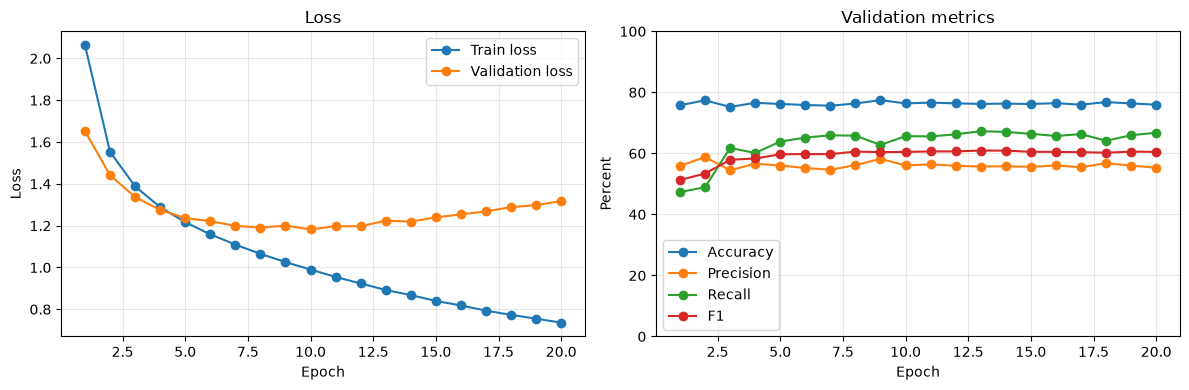

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

validation_metrics = {
    "val_accuracy": "Accuracy",
    "val_precision": "Precision",
    "val_recall": "Recall",
    "val_f1": "F1",
}
for column, label in validation_metrics.items():
    axes[1].plot(history_df["epoch"], history_df[column] * 100, marker="o", label=label)

axes[1].set_title("Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Percent")
axes[1].set_ylim(0, 100)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Prediction helpers

`mask_text(...)` accepts normal raw text, tokenizes it with the same tokenizer, predicts token labels, merges adjacent predicted PII tokens, and replaces each span with an entity mask.

In [11]:
def label_to_entity(label):
    if label == "O":
        return None
    return normalize_entity_label(label.split("-", 1)[-1])

def predict_labels_for_text(text):
    text = normalize_text(text)
    tokens, offsets = tokenize_with_offsets(text)
    if not tokens:
        return text, tokens, offsets, []

    input_ids = torch.tensor([encode_tokens(tokens)], dtype=torch.long).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(input_ids)
        pred_ids = logits.argmax(dim=-1).squeeze(0).cpu().numpy().tolist()
    pred_labels = [id_to_label[pred_id] for pred_id in pred_ids]
    return text, tokens, offsets, pred_labels

def prediction_spans(offsets, labels):
    spans = []
    current = None
    for (start, end), label in zip(offsets, labels):
        entity = label_to_entity(label)
        if entity is None:
            if current:
                spans.append(current)
                current = None
            continue

        begins_new = label.startswith("B-") or current is None or current["label"] != entity or start > current["end"] + 1
        if begins_new:
            if current:
                spans.append(current)
            current = {"start": start, "end": end, "label": entity}
        else:
            current["end"] = end

    if current:
        spans.append(current)
    return spans

def apply_masks(text, spans):
    if not spans:
        return text
    pieces = []
    cursor = 0
    for span in spans:
        pieces.append(text[cursor:span["start"]])
        pieces.append(f"[{span['label']}]")
        cursor = span["end"]
    pieces.append(text[cursor:])
    return normalize_text("".join(pieces))

def mask_text(text, return_details=False):
    normalized, tokens, offsets, pred_labels = predict_labels_for_text(text)
    spans = prediction_spans(offsets, pred_labels)
    masked = apply_masks(normalized, spans)
    if return_details:
        return {
            "input_text": normalized,
            "masked_text": masked,
            "tokens": tokens,
            "predicted_labels": pred_labels,
            "predicted_spans": spans,
        }
    return masked

#### Qualitative masking examples

These examples come from the validation split. They show the full source text, the dataset target/mask, and the model-predicted masked text so the masking behavior can be checked visually.

In [12]:
def has_text_value(value):
    if value is None:
        return False
    if isinstance(value, float) and pd.isna(value):
        return False
    return bool(str(value).strip())

def reference_mask_for_example(example):
    target_text = example.get("target_text")
    if has_text_value(target_text):
        return normalize_text(target_text)
    return apply_masks(example["source_text"], example["spans"])

qualitative_rows = []
for example in val_examples[:5]:
    qualitative_rows.append(
        {
            "original_source_text": example["source_text"],
            "dataset_target_or_mask": reference_mask_for_example(example),
            "model_predicted_mask": mask_text(example["source_text"]),
        }
    )

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(qualitative_rows))

,original_source_text,dataset_target_or_mask,model_predicted_mask
0,ool agrees to provide suitable facilities at 256 and maintain a conducive learning environment. The literacy program provider will deliver tailored literacy lessons at the agreed schedule.</term> <term>Financials: The school shall pay a monthly fee of GBP for the provision of the literacy program services.</term> <term>Termination: Either party may terminate this contract with a 30-day written notice in case of any breach of terms.</term> </terms> </literacy_program_contract> ```,ool agrees to provide suitable facilities at [BUILDING] and maintain a conducive learning environment. The literacy program provider will deliver tailored literacy lessons at the agreed schedule.</term> <term>Financials: The school shall pay a monthly fee of GBP for the provision of the literacy program services.</term> <term>Termination: Either party may terminate this contract with a 30-day written notice in case of any breach of terms.</term> </terms> </literacy_program_contract> ```,ool agrees to provide suitable facilities at [TIME] and maintain a conducive learning environment. The literacy program provider will deliver tailored literacy lessons at the agreed schedule.</term> <term>Financials: The school shall pay a monthly fee of GBP for the provision of the literacy program services.</term> <term>Termination: Either party may terminate this contract with a 30-day written notice in case of any breach of terms.</term> </terms> </literacy_program_contract> ```
1,"```yaml Compliance_Report: Title: ESG Compliance Report Date: 2046-09-04T00:00:00 Time: 21:40:42 Individuals: - Name: Esquire Date_of_Birth: May 7th, 1984 Driver_License: Q03JN6780563 Telephone: 064 413-3163 Passport: x$o2nD""ffH - Name:",```yaml Compliance_Report: Title: ESG Compliance Report Date: [DATE] Time: [TIME] Individuals: - Name: [TITLE] Date_of_Birth: [BOD] Driver_License: [DRIVERLICENSE] Telephone: [TEL] Passport: [PASS] - Name:,"```yaml Compliance_Report: Title: ESG Compliance Report Date: [DATE] Individuals: - [TIME]: Esquire Date_of_Birth: May 7th, 1984 [BOD]6780563 [DRIVERLICENSE]: x$o2nD""ffH - [TEL]"
2,--- title: Title IX Records Request for Access to Title IX Investigation Records requestor_name: Ilon Chloè Carbo requestor_title: Ambassador requestor_username: chloè requestor_social_number: 006 311 0101 requestor_id_card: SZ32965JK requestor_driver_license: ILON9-609179-IC-489 requestor_ip: 192.156.58.250 requestor_time: 4 AM investigator_name: Raymund Kapor investigator_title: Baron investigator_username: raymund.kapor31 investigator_social_number: 551-176-4226 investigator_i,--- title: Title IX Records Request for Access to Title IX Investigation Records requestor_name: [GIVENNAME1] [GIVENNAME2] [LASTNAME1] requestor_title: [TITLE] requestor_username: [USERNAME] requestor_social_number: [SOCIALNUMBER] requestor_id_card: [IDCARD] requestor_driver_license: [DRIVERLICENSE] requestor_ip: [IP] requestor_time: [TIME] investigator_name: [GIVENNAME1] [LASTNAME1] investigator_title: [TITLE] investigator_username: [USERNAME] investigator_social_number: [SOCIALNUMBER] investigator_i,--- title: Title IX Records Request for Access to Title IX Investigation Records requestor_name: Ilon Chloè Carbo requestor_title: [TITLE] [TITLE]_username: chloè requestor_social_number: [SOCIALNUMBER]_id_card: SZ32965[IDCARD][PASS]: ILON[DRIVERLICENSE]-489 requestor_ip: [IP] [PASS]_time: [TIME] investigator_name: Raymund Kapor investigator_title: Baron investigator_username: raymund.kapor31 investigator[USERNAME]: 551-176-4226 investigator_i
3,"11 and 03:31:04 will be in charge of scheduling routine security audits and compliance checks. Conclusion: By implementing these robust measures, we aim to strengthen patient data privacy within health informatics platforms and ensure the trust and confidence of patients in the secure handling of their sensitive information. (Note: This is a fictional proposal created for the purpose of thi

#### Save trained model

The final block saves the trained model weights, model configuration, preprocessing configuration, token vocabulary, label map, and final validation metrics.

In [13]:
ARTIFACT_DIR = REPO_ROOT / "model" / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACT_DIR / "pii_masking_bilstm.pt"
model_config_path = ARTIFACT_DIR / "pii_masking_bilstm_config.json"
vocab_path = ARTIFACT_DIR / "token_vocab.json"
label_map_path = ARTIFACT_DIR / "label_map.json"
config_path = ARTIFACT_DIR / "preprocessing_config.json"
metrics_path = ARTIFACT_DIR / "final_eval_metrics.json"

model_config = {
    "architecture": "Embedding -> BiLSTM -> Linear token classifier",
    "vocab_size": len(token_to_id),
    "num_labels": len(label_to_id),
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "dropout": DROPOUT,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "train_fraction": TRAIN_FRACTION,
}

preprocessing_config = {
    "dataset_name": DATASET_NAME,
    "source_column": "source_text",
    "label_sources": [column for column in ["privacy_mask", "span_labels"] if column in df.columns],
    "target_text_usage": "reference_only_not_training_input" if "target_text" in df.columns else "not_available",
    "language_filter": LANGUAGE_FILTER,
    "text_truncation": "disabled",
    "padding": "dynamic per batch in collate_batch",
    "token_pattern": TOKEN_PATTERN.pattern,
    "token_feature_rules": ["EMAIL_PATTERN", "NUMBER_PATTERN", "ALNUM_PATTERN", "lowercase fallback"],
    "label_format": "type-specific BIO labels from privacy_mask/span_labels",
}

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "model_config": model_config,
        "preprocessing_config": preprocessing_config,
        "label_to_id": label_to_id,
        "token_to_id": token_to_id,
        "final_eval_metrics": final_eval_metrics,
    },
    model_path,
)

with open(model_config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=2)

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(token_to_id, f, indent=2)

id_to_label_json = {str(label_id): label for label_id, label in id_to_label.items()}
with open(label_map_path, "w", encoding="utf-8") as f:
    json.dump({"label_to_id": label_to_id, "id_to_label": id_to_label_json}, f, indent=2)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, indent=2)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(final_eval_metrics, f, indent=2)

print("Saved model:", model_path)
print("Saved model config:", model_config_path)
print("Saved vocabulary:", vocab_path)
print("Saved label map:", label_map_path)
print("Saved preprocessing config:", config_path)
print("Saved final evaluation metrics:", metrics_path)

Saved model: <REPO_ROOT>/model/artifacts/pii_masking_bilstm.pt
Saved model config: <REPO_ROOT>/model/artifacts/pii_masking_bilstm_config.json
Saved vocabulary: <REPO_ROOT>/model/artifacts/token_vocab.json
Saved label map: <REPO_ROOT>/model/artifacts/label_map.json
Saved preprocessing config: <REPO_ROOT>/model/artifacts/preprocessing_config.json
Saved final evaluation metrics: <REPO_ROOT>/model/artifacts/final_eval_metrics.json
